<a href="https://colab.research.google.com/github/yassiiirrrr/Short-Term-Solar-Energy-Generation-Forecasting-Using-Weather-Data-and-Machine-Learning-Model/blob/main/major_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv('train.csv')

df['timestamp'] = pd.to_datetime(df['timestamp'])

df = df.sort_values('timestamp').reset_index(drop=True)

df['hour_sin'] = np.sin(2 * np.pi * df['timestamp'].dt.hour / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['timestamp'].dt.hour / 24)

df['month_sin'] = np.sin(2 * np.pi * df['timestamp'].dt.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df['timestamp'].dt.month / 12)

df.to_csv('model_ready_train.csv', index=False)
print("Task 2 complete: model_ready_train.csv created successfully!")

Task 2 complete: model_ready_train.csv created successfully!


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('model_ready_train.csv')


target = 'Active_Power'

features = [col for col in df.columns if col not in ['timestamp', target]]

split_idx = int(len(df) * 0.8)
train_set = df.iloc[:split_idx]
val_set = df.iloc[split_idx:]

X_train, y_train = train_set[features], train_set[target]
X_val, y_val = val_set[features], val_set[target]

print(f"Training on {len(X_train)} rows. Validating on {len(X_val)} rows...")


rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)


y_pred = rf_model.predict(X_val)


rmse = np.sqrt(mean_squared_error(y_val, y_pred))
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print("\n--- Baseline Model Results ---")
print(f"R-squared (R2): {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} kW")
print(f"Mean Absolute Error (MAE): {mae:.4f} kW")

Training on 153900 rows. Validating on 38475 rows...

--- Baseline Model Results ---
R-squared (R2): 0.9651
Root Mean Squared Error (RMSE): 1.5450 kW
Mean Absolute Error (MAE): 0.7838 kW


In [ ]:
import pandas as pd
import numpy as np
import joblib
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


df = pd.read_csv('model_ready_train.csv')


target = 'Active_Power'
features = [col for col in df.columns if col not in ['timestamp', target]]


split_idx = int(len(df) * 0.8)
train_set = df.iloc[:split_idx]
val_set = df.iloc[split_idx:]

X_train, y_train = train_set[features], train_set[target]
X_val, y_val = val_set[features], val_set[target]

print(f"Training XGBoost on {len(X_train)} rows...")


xgb_model = XGBRegressor(
    n_estimators=150,
    learning_rate=0.1,
    max_depth=7,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)


y_pred = xgb_model.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print("\n--- XGBoost Model Results ---")
print(f"R-squared (R2): {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} kW")
print(f"Mean Absolute Error (MAE): {mae:.4f} kW")

joblib.dump(xgb_model, 'xgboost_solar_model.pkl')
print("\nModel saved successfully as 'xgboost_solar_model.pkl'")

Training XGBoost on 153900 rows...

--- XGBoost Model Results ---
R-squared (R2): 0.9627
Root Mean Squared Error (RMSE): 1.5968 kW
Mean Absolute Error (MAE): 0.8090 kW

Model saved successfully as 'xgboost_solar_model.pkl'


/tmp/ipykernel_1932/3579960727.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')


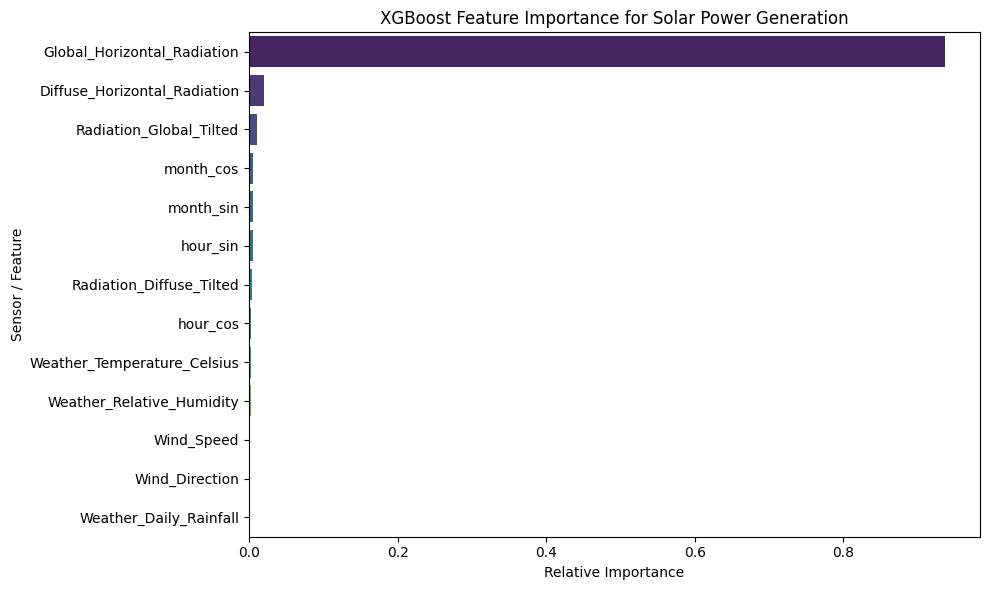

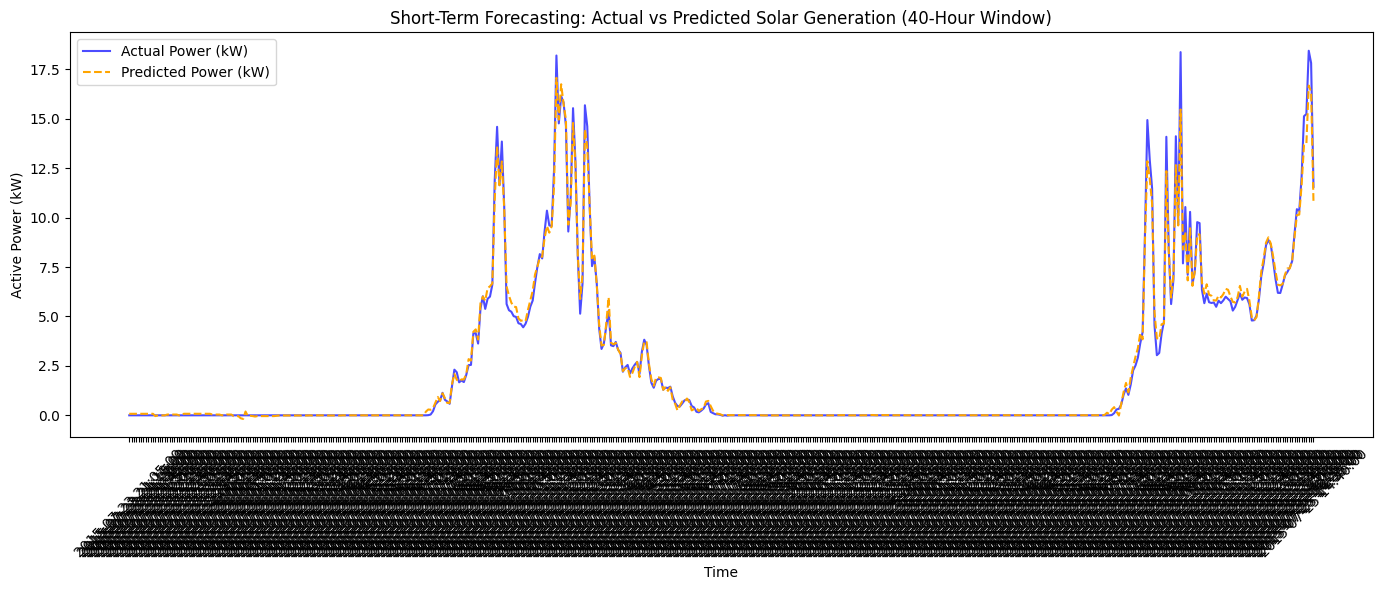

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# 1. Load the dataset and model
df = pd.read_csv('model_ready_train.csv')
xgb_model = joblib.load('xgboost_solar_model.pkl')

target = 'Active_Power'
features = [col for col in df.columns if col not in ['timestamp', target]]

# 2. Extract Feature Importance
importance = xgb_model.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': features, 'Importance': importance})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# 3. Plot Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
plt.title('XGBoost Feature Importance for Solar Power Generation')
plt.xlabel('Relative Importance')
plt.ylabel('Sensor / Feature')
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()

# 4. Plot Actual vs Predicted (Showing a 2-day sample for visual clarity)
split_idx = int(len(df) * 0.8)
val_set = df.iloc[split_idx:].copy()

X_val = val_set[features]
val_set['Predicted_Power'] = xgb_model.predict(X_val)

# Select a 500-row slice (~40 hours) to make the lines readable
sample_val = val_set.iloc[1000:1500]

plt.figure(figsize=(14, 6))
plt.plot(sample_val['timestamp'], sample_val['Active_Power'], label='Actual Power (kW)', color='blue', alpha=0.7)
plt.plot(sample_val['timestamp'], sample_val['Predicted_Power'], label='Predicted Power (kW)', color='orange', linestyle='dashed')
plt.title('Short-Term Forecasting: Actual vs Predicted Solar Generation (40-Hour Window)')
plt.xlabel('Time')
plt.ylabel('Active Power (kW)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('actual_vs_predicted.png')
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# Create the folder structure using bash commands
!mkdir -p /content/drive/MyDrive/Solar_Project/data
!mkdir -p /content/drive/MyDrive/Solar_Project/src
print("Folders created successfully.")

Mounted at /content/drive
Folders created successfully.


In [ ]:
%%writefile /content/drive/MyDrive/Solar_Project/src/data_preprocessing.py
import numpy as np
import pandas as pd

def preprocess_data(file_path):
    df = pd.read_csv(file_path)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df = df.sort_values('timestamp').reset_index(drop=True)

    df['hour_sin'] = np.sin(2 * np.pi * df['timestamp'].dt.hour / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['timestamp'].dt.hour / 24)
    df['month_sin'] = np.sin(2 * np.pi * df['timestamp'].dt.month / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['timestamp'].dt.month / 12)

    target = 'Active_Power'
    features = [col for col in df.columns if col not in ['timestamp', target]]

    split_idx = int(len(df) * 0.8)
    train_set = df.iloc[:split_idx].copy()
    val_set = df.iloc[split_idx:].copy()

    X_train, y_train = train_set[features], train_set[target]
    X_val, y_val = val_set[features], val_set[target]

    return X_train, X_val, y_train, y_val, features, val_set

Writing /content/drive/MyDrive/Solar_Project/src/data_preprocessing.py


In [ ]:
%%writefile /content/drive/MyDrive/Solar_Project/src/model_training.py
import joblib
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

def train_and_save_rf(X_train, y_train, save_path='rf_solar_model.pkl'):
    rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)
    joblib.dump(rf_model, save_path)
    return rf_model

def train_and_save_xgb(X_train, y_train, save_path='xgboost_solar_model.pkl'):
    xgb_model = XGBRegressor(n_estimators=150, learning_rate=0.1, max_depth=7, random_state=42, n_jobs=-1)
    xgb_model.fit(X_train, y_train)
    joblib.dump(xgb_model, save_path)
    return xgb_model

Writing /content/drive/MyDrive/Solar_Project/src/model_training.py


In [ ]:
%%writefile /content/drive/MyDrive/Solar_Project/main.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from src.data_preprocessing import preprocess_data
from src.model_training import train_and_save_rf, train_and_save_xgb

def evaluate_model(name, model, X_val, y_val):
    y_pred = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    print(f"\n--- {name} Results ---")
    print(f"R2: {r2:.4f} | RMSE: {rmse:.4f} kW | MAE: {mae:.4f} kW")
    return y_pred

if __name__ == "__main__":
    X_train, X_val, y_train, y_val, features, val_set = preprocess_data('data/train.csv')
    print(f"Training on {len(X_train)} rows. Validating on {len(X_val)} rows...")

    rf_model = train_and_save_rf(X_train, y_train, 'rf_solar_model.pkl')
    xgb_model = train_and_save_xgb(X_train, y_train, 'xgboost_solar_model.pkl')

    evaluate_model("Random Forest", rf_model, X_val, y_val)
    xgb_preds = evaluate_model("XGBoost", xgb_model, X_val, y_val)

    importance = xgb_model.feature_importances_
    feature_imp_df = pd.DataFrame({'Feature': features, 'Importance': importance}).sort_values(by='Importance', ascending=False)

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
    plt.title('XGBoost Feature Importance')
    plt.tight_layout()
    plt.savefig('feature_importance.png')

    val_set['Predicted_Power'] = xgb_preds
    sample_val = val_set.iloc[1000:1500]

    plt.figure(figsize=(14, 6))
    plt.plot(sample_val['timestamp'], sample_val['Active_Power'], label='Actual', color='blue', alpha=0.7)
    plt.plot(sample_val['timestamp'], sample_val['Predicted_Power'], label='Predicted', color='orange', linestyle='dashed')
    plt.title('Actual vs Predicted Solar Generation (40-Hour Window)')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('actual_vs_predicted.png')

    print("\nPipeline complete. Models and visualizations saved to directory.")

Overwriting /content/drive/MyDrive/Solar_Project/main.py


In [ ]:
%cd /content/drive/MyDrive/Solar_Project
!python main.py

/content/drive/MyDrive/Solar_Project
Training on 153900 rows. Validating on 38475 rows...

--- Random Forest Results ---
R2: 0.9651 | RMSE: 1.5450 kW | MAE: 0.7838 kW

--- XGBoost Results ---
R2: 0.9627 | RMSE: 1.5968 kW | MAE: 0.8090 kW

Pipeline complete. Models and visualizations saved to directory.
